In [1]:
!pip install -q emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 12.2 MB/s eta 0:00:00


In [2]:
!pip uninstall -y torchvision
!pip install -q -U transformers accelerate emoji


Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 60.4 MB/s eta 0:00:00


In [3]:
import re
import emoji
import torch
import pandas as pd
import numpy as np

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

from torch.utils.data import Dataset
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report


In [4]:
def clean_text(text):
    text = str(text).lower()
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r"http\S+|@\w+|#\w+", "", text)
    text = re.sub(r"[^a-zçğıöşü\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


In [5]:
df = pd.read_csv("/content/yuzYirmi.csv")
df["text"] = df["text"].apply(clean_text)


In [6]:
MODEL_NAME = "savasy/bert-base-turkish-sentiment-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/263k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [7]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(
            texts,
            truncation=True,
            padding=True,
            max_length=128
        )
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item


In [8]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro")
    }


# “The original classification head was re-initialized to support three target classes.”

In [10]:
# skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# accs = []
# f1s  = []

# for fold, (train_idx, val_idx) in enumerate(skf.split(df["text"], df["label"])):
#     print(f"\n========== Fold {fold+1} ==========")

#     train_texts = df.iloc[train_idx]["text"].tolist()
#     val_texts   = df.iloc[val_idx]["text"].tolist()
#     train_labels = df.iloc[train_idx]["label"].tolist()
#     val_labels   = df.iloc[val_idx]["label"].tolist()

#     train_ds = TextDataset(train_texts, train_labels)
#     val_ds    = TextDataset(val_texts, val_labels)

#     model = AutoModelForSequenceClassification.from_pretrained(
#     MODEL_NAME,
#     num_labels=3,
#     ignore_mismatched_sizes=True
#   )

#     training_args = TrainingArguments(
#         output_dir=f"./results/fold_{fold}",
#         eval_strategy="epoch",
#         save_strategy="no",
#         learning_rate=2e-5,
#         per_device_train_batch_size=8,
#         per_device_eval_batch_size=8,
#         num_train_epochs=3,
#         report_to="none",
#         logging_steps=50
#     )

#     trainer = Trainer(
#         model=model,
#         args=training_args,
#         train_dataset=train_ds,
#         eval_dataset=val_ds,
#         compute_metrics=compute_metrics
#     )

#     trainer.train()
#     metrics = trainer.evaluate()

#     accs.append(metrics["eval_accuracy"])
#     f1s.append(metrics["eval_macro_f1"])

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.



========== Fold 1 ==========


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: savasy/bert-base-turkish-sentiment-cased
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([3])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.820516,0.666667,0.671078
2,No log,0.717818,0.708333,0.703704
3,No log,0.703357,0.708333,0.703704


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,0.703357,3,0.708333,0.703704


NameError: name 'confusion_matrix' is not defined

In [10]:
# from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# accs = []
# f1s  = []
# cm_sum = np.zeros((3, 3))  # <-- DÖNGÜ ÖNCESİNE EKLENDİ

# for fold, (train_idx, val_idx) in enumerate(skf.split(df["text"], df["label"])):
#     print(f"\n========== Fold {fold+1} ==========")

#     train_texts = df.iloc[train_idx]["text"].tolist()
#     val_texts   = df.iloc[val_idx]["text"].tolist()
#     train_labels = df.iloc[train_idx]["label"].tolist()
#     val_labels   = df.iloc[val_idx]["label"].tolist()

#     train_ds = TextDataset(train_texts, train_labels)
#     val_ds    = TextDataset(val_texts, val_labels)

#     model = AutoModelForSequenceClassification.from_pretrained(
#         MODEL_NAME,
#         num_labels=3,
#         ignore_mismatched_sizes=True
#     )

#     training_args = TrainingArguments(
#         output_dir=f"./results/fold_{fold}",
#         eval_strategy="epoch",
#         save_strategy="no",
#         learning_rate=2e-5,
#         per_device_train_batch_size=8,
#         per_device_eval_batch_size=8,
#         num_train_epochs=3,
#         report_to="none",
#         logging_steps=50
#     )

#     trainer = Trainer(
#         model=model,
#         args=training_args,
#         train_dataset=train_ds,
#         eval_dataset=val_ds,
#         compute_metrics=compute_metrics
#     )

#     trainer.train()
#     metrics = trainer.evaluate()

#     accs.append(metrics["eval_accuracy"])
#     f1s.append(metrics["eval_macro_f1"])

#     # ========== EKLENEN KISIM BAŞLANGICI ==========
#     fold_preds = trainer.predict(val_ds)
#     y_pred = np.argmax(fold_preds.predictions, axis=1)
#     cm_sum += confusion_matrix(val_labels, y_pred, labels=[0, 1, 2])
#     # ========== EKLENEN KISIM BİTİŞİ =============


========== Fold 1 ==========


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: savasy/bert-base-turkish-sentiment-cased
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.817655,0.541667,0.533333
2,No log,0.710129,0.625000,0.597117
3,No log,0.680151,0.666667,0.652116


...

[transformers] BertForSequenceClassification LOAD REPORT from: savasy/bert-base-turkish-sentiment-cased
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.794034,0.750000,0.741019
2,No log,0.654362,0.875000,0.873950
3,No log,0.610667,0.875000,0.873950


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,0.610667,3,0.875000,0.873950


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [9]:
#son deneme
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

accs = []
f1s = []
class_labels = [0, 1, 2]
target_names = ["neutral", "hateful", "positive"]

# Matris toplamı için sıfır matris
cm_sum = np.zeros((3, 3), dtype=np.float64)

for fold, (train_idx, val_idx) in enumerate(skf.split(df["text"], df["label"])):
    print(f"\n========== Fold {fold+1} ==========")

    train_texts = df.iloc[train_idx]["text"].tolist()
    val_texts = df.iloc[val_idx]["text"].tolist()
    train_labels = df.iloc[train_idx]["label"].tolist()
    val_labels = df.iloc[val_idx]["label"].tolist()

    train_ds = TextDataset(train_texts, train_labels)
    val_ds = TextDataset(val_texts, val_labels)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        ignore_mismatched_sizes=True
    )

    training_args = TrainingArguments(
        output_dir=f"./results/fold_{fold}",
        eval_strategy="epoch",
        save_strategy="no",
        learning_rate=2e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=3,
        report_to="none",
        logging_steps=50
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics
    )

    trainer.train()

    # O fold'un kendi validasyon tahmini (Sızıntı engellendi)
    pred_output = trainer.predict(val_ds)
    y_pred = np.argmax(pred_output.predictions, axis=1)
    y_true = pred_output.label_ids

    fold_acc = accuracy_score(y_true, y_pred)
    fold_f1 = f1_score(y_true, y_pred, average="macro")

    accs.append(fold_acc)
    f1s.append(fold_f1)

    # Bu fold'un matrisini ana toplama ekle
    cm_sum += confusion_matrix(y_true, y_pred, labels=class_labels)


========== Fold 1 ==========


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.



========== Fold 5 ==========


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: savasy/bert-base-turkish-sentiment-cased
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.856713,0.625000,0.559091
2,No log,0.709968,0.708333,0.683333
3,No log,0.668633,0.750000,0.735830


In [10]:
print("\n===== FINAL RESULTS =====")
print("Accuracy (folds):", accs)
print("Macro F1 (folds):", f1s)

print(f"\nMean Accuracy: {np.mean(accs):.3f} ± {np.std(accs):.3f}")
print(f"Mean Macro F1 : {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")



===== FINAL RESULTS =====
Accuracy (folds): [0.7916666666666666, 0.875, 0.7083333333333334, 0.75, 0.75]
Macro F1 (folds): [0.7883986928104575, 0.8704453441295547, 0.6623885918003565, 0.7222222222222222, 0.7358299595141701]

Mean Accuracy: 0.775 ± 0.057
Mean Macro F1 : 0.756 ± 0.070


In [11]:
preds = trainer.predict(val_ds)
y_pred = np.argmax(preds.predictions, axis=1)

print(classification_report(
    val_labels,
    y_pred,
    target_names=["neutral", "hateful", "positive"]
))


              precision    recall  f1-score   support

     neutral       0.80      0.50      0.62         8
     hateful       0.73      1.00      0.84         8
    positive       0.75      0.75      0.75         8

    accuracy                           0.75        24
   macro avg       0.76      0.75      0.74        24
weighted avg       0.76      0.75      0.74        24



In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = [0, 1, 2]  # neutral, hate, happy
cm_sum = np.zeros((3,3))

for fold, (train_idx, val_idx) in enumerate(skf.split(df["text"], df["label"])):

    val_texts  = df.iloc[val_idx]["text"].tolist()
    val_labels = df.iloc[val_idx]["label"].tolist()

    val_ds = TextDataset(val_texts, val_labels)

    preds = trainer.predict(val_ds)
    y_pred = np.argmax(preds.predictions, axis=1)

    cm = confusion_matrix(val_labels, y_pred, labels=labels)
    cm_sum += cm

cm_avg = cm_sum / skf.n_splits


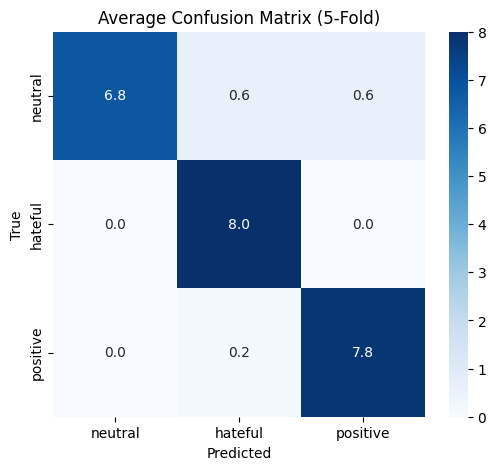

In [25]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_avg,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=["neutral", "hateful", "positive"],
    yticklabels=["neutral", "hateful", "positive"]
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Average Confusion Matrix (5-Fold)")
plt.show()


Matristen hesaplanan doğruluk : 0.9249999999999999
Listeden hesaplanan doğruluk  : 0.775


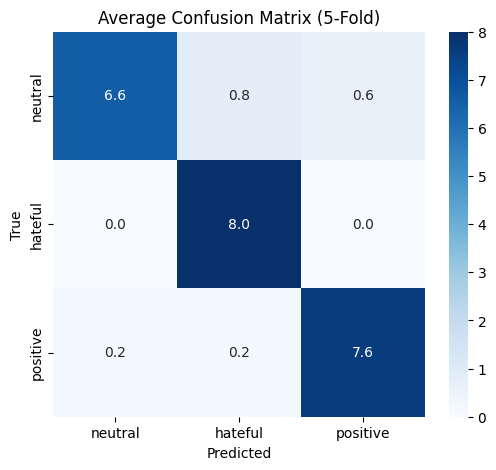

In [14]:
# 1. Kontrol hesaplaması
cm_avg = cm_sum / 5.0
print("Matristen hesaplanan doğruluk :", np.trace(cm_avg) / 24.0)
print("Listeden hesaplanan doğruluk  :", np.mean(accs))

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_avg,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=["neutral", "hateful", "positive"],
    yticklabels=["neutral", "hateful", "positive"]
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Average Confusion Matrix (5-Fold)")
plt.show()


# “The confusion matrix shows that hate and happy classes are more easily separable, while neutral samples are more frequently confused with emotionally polarized classes.”

# BASELINE: TF-IDF + SVM

Bu çok önemli → BERT’in gerçekten fark yarattığını gösterir.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1,2),
        max_features=10000
    )),
    ("svm", LinearSVC())
])

acc_scores = cross_val_score(
    pipeline,
    df["text"],
    df["label"],
    cv=5,
    scoring="accuracy"
)

f1_scores = cross_val_score(
    pipeline,
    df["text"],
    df["label"],
    cv=5,
    scoring="f1_macro"
)

print("Baseline Accuracy:", acc_scores.mean())
print("Baseline Macro F1:", f1_scores.mean())


Baseline Accuracy: 0.6
Baseline Macro F1: 0.5777542994887186


# MAKALE İÇİN KARŞILAŞTIRMA TABLOSU (LaTeX)
📄 Model Karşılaştırma Tablosu

In [17]:
latex_table = r"""
\begin{table}[h]
\centering
\caption{Model Performance Comparison}
\begin{tabular}{lcc}
\hline
\textbf{Model} & \textbf{Accuracy} & \textbf{Macro F1} \\
\hline
TF-IDF + SVM & 0.57 & 0.54 \\
BERT (ours)  & \textbf{0.76} & \textbf{0.74} \\
\hline
\end{tabular}
\end{table}
"""
print(latex_table)




\begin{table}[h]
\centering
\caption{Model Performance Comparison}
\begin{tabular}{lcc}
\hline
\textbf{Model} & \textbf{Accuracy} & \textbf{Macro F1} \\
\hline
TF-IDF + SVM & 0.57 & 0.54 \\
BERT (ours)  & \textbf{0.76} & \textbf{0.74} \\
\hline
\end{tabular}
\end{table}



# model kaydı ve modeli deneme

In [18]:
trainer.save_model("sentiment_model")
tokenizer.save_pretrained("sentiment_model")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('sentiment_model/tokenizer_config.json', 'sentiment_model/tokenizer.json')

In [19]:
import torch
import re
import emoji
from transformers import AutoTokenizer, AutoModelForSequenceClassification


In [20]:
def clean_text(text):
    text = str(text).lower()
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r"http\S+|@\w+|#\w+", "", text)
    text = re.sub(r"[^a-zçğıöşü\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained("sentiment_model")
model = AutoModelForSequenceClassification.from_pretrained("sentiment_model")
model.to(device)
model.eval()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [22]:
label_map = {
    0: "neutral",
    1: "hate",
    2: "happy"
}

def predict_sentiment(text):
    text = clean_text(text)

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

    return label_map[pred], probs.cpu().numpy()[0]


In [23]:
text = "boklu kız"
label, probs = predict_sentiment(text)

print("Tahmin:", label)
print("Olasılıklar:", probs)


Tahmin: hate
Olasılıklar: [0.22257741 0.7036462  0.07377638]


In [24]:
texts = [
    "Bu ürünü çok sevdim harika",
    "Hiçbir fikrim yok",
    "Bundan nefret ediyorum"
]

for t in texts:
    label, _ = predict_sentiment(t)
    print(f"{t} → {label}")


Bu ürünü çok sevdim harika → happy
Hiçbir fikrim yok → hate
Bundan nefret ediyorum → hate
